# **Clinical Data – project, Week 1**

by FANI TZINA - MEI Master's program, AUTH

# **Cardiovascular Disease Prediction**

Cardiovascular diseases (CVDs) are the number 1 cause of death globally, taking an estimated 17.9 million lives each year, which accounts for 31% of all deaths worldwide. Four out of 5 CVD deaths are due to heart attacks and strokes, and one-third of these deaths occur prematurely in people under 70 years of age.

Heart failure is a common event caused by CVDs and this dataset contains 11 features that can be used to predict a possible heart disease.
People with cardiovascular disease or who are at high cardiovascular risk (due to the presence of one or more risk factors such as hypertension, diabetes, hyperlipidaemia or already established disease) need early detection and management. ((((wherein a machine learning model can be of great help.))))


***Attribute Information:***

**Age**: age of the patient [years]

**Sex**: sex of the patient [M: Male, F: Female]

**Chest Pain Type**: chest pain type [TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic]

**Resting BP**: resting blood pressure [mm Hg]

**Cholesterol**: serum cholesterol [mm/dl]

**Fasting BS**: fasting blood sugar [1: if Fasting BS > 120 mg/dl, 0: otherwise]

**Resting ECG**: resting electrocardiogram results
[Normal: Normal, ST: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV), LVH: showing probable or definite left ventricular hypertrophy by Estes' criteria].

**Max HR**: maximum heart rate achieved [Numeric value between 60 and 202]

**Exercise Angina**: exercise-induced angina [Y: Yes, N: No]

**Old peak**: old peak = ST [Numeric value measured in depression]

**ST _Slope**: the slope of the peak exercise ST segment [Up: upsloping, Flat: flat, Down: down sloping]

**Heart Disease**: output class [1: heart disease, 0: Normal]

In [ ]:
pip install wfdb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 96.0 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.


In [ ]:
import wfdb
from wfdb import processing
from IPython.display import display
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
import os
import shutil
import posixpath
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df = pd.read_csv('/content/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


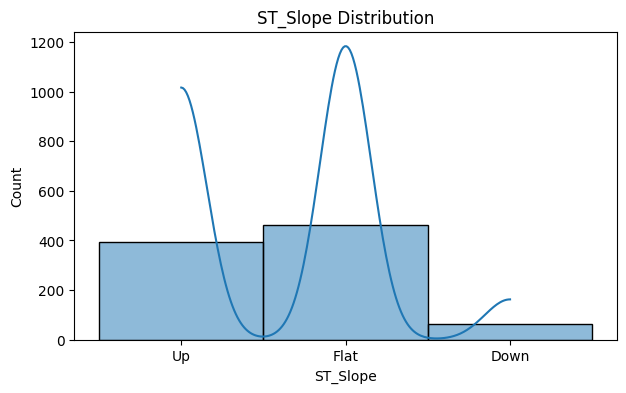

In [ ]:
categorical_vars = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# Histogram – Age
plt.figure(figsize=(7,4))
sns.histplot(df['ST_Slope'], bins=20, kde=True)
plt.title("ST_Slope Distribution")
plt.xlabel("ST_Slope")
plt.ylabel("Count")
plt.show()

In [ ]:
print(df.shape)

(918, 12)


SHAPE: 918 x 12

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
df.describe(include='object') # summary for categorical features

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


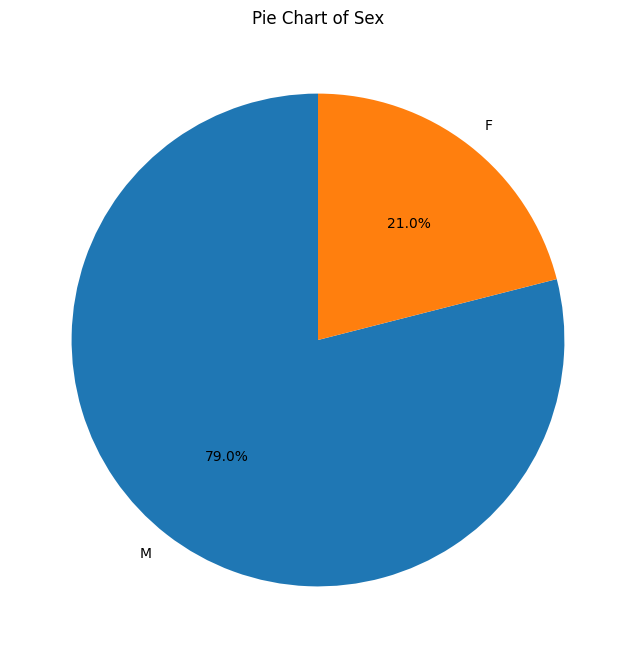

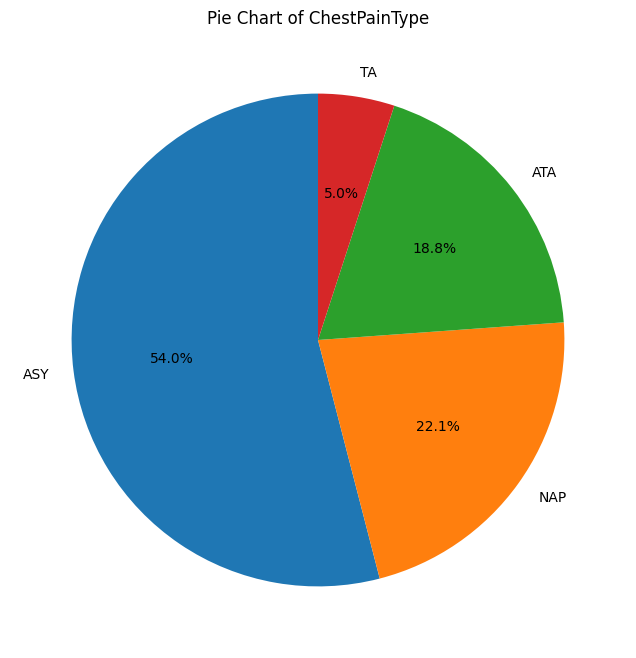

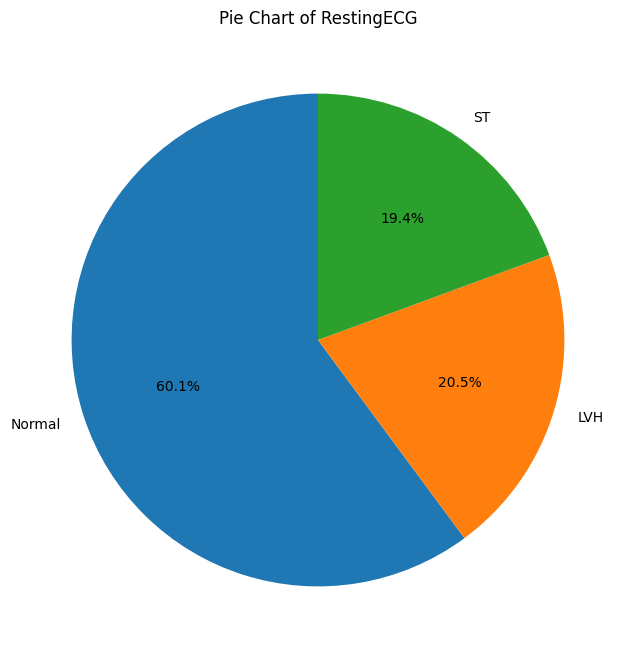

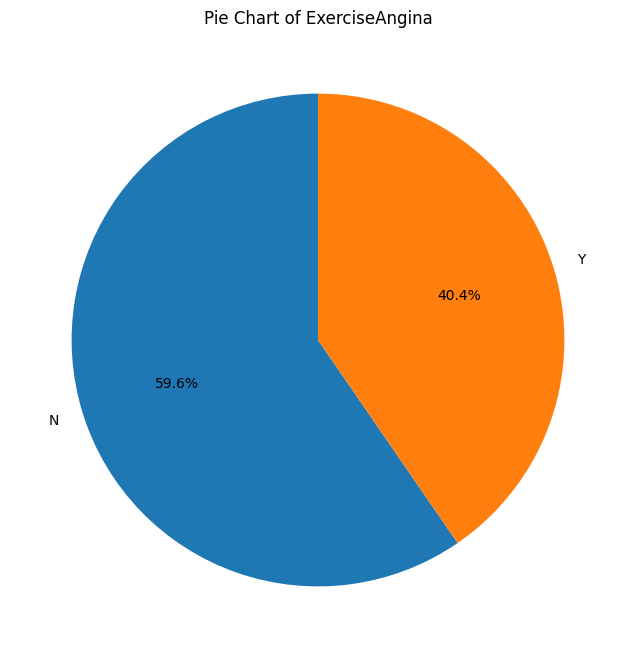

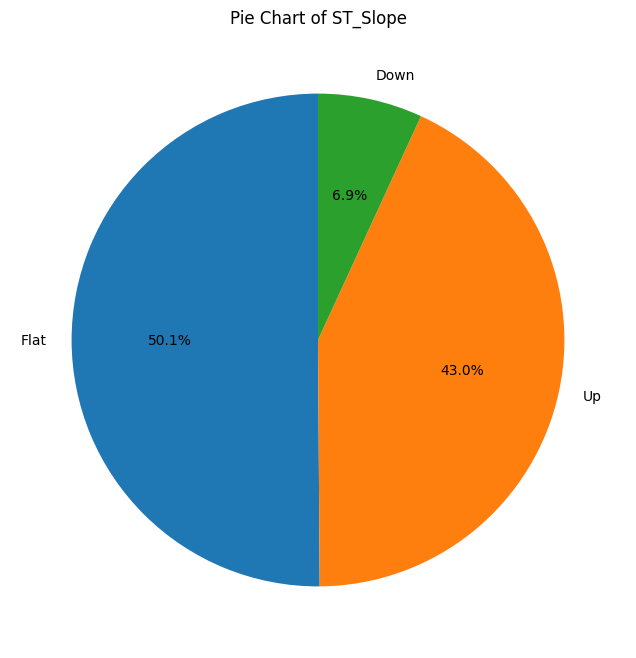

In [ ]:
categorical_features = df.select_dtypes(include=['object', 'category']).columns
#categorical_features = df.select_dtypes(include=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']).columns
for feature in categorical_features:
    plt.figure(figsize=(8, 8))
    df[feature].value_counts().plot.pie(autopct='%1.1f%%', startangle=90)
    plt.title(f'Pie Chart of {feature}')
    plt.ylabel('')  # Hide the y-label
    plt.show()

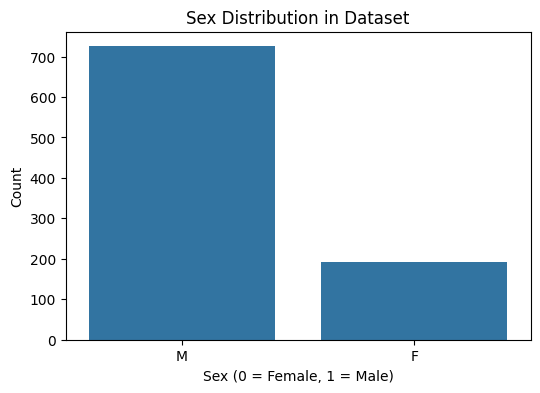

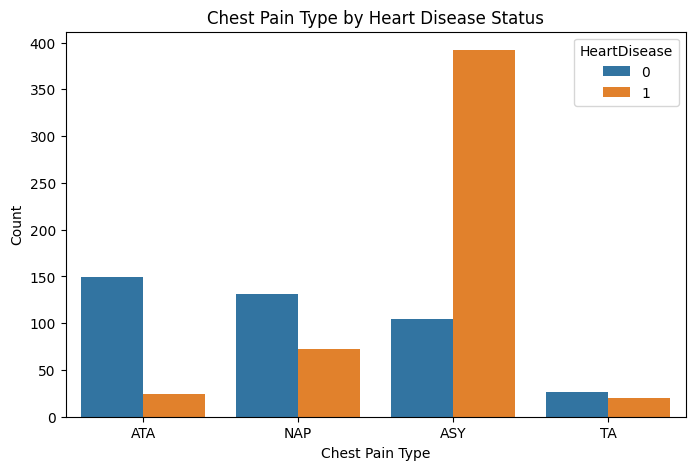

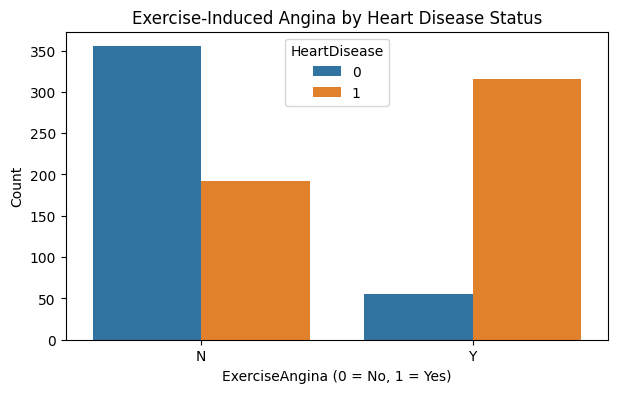

In [ ]:

# Bar Plot – Sex Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Sex', data=df)
plt.title("Sex Distribution in Dataset")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Count")
plt.show()


# Countplot – ChestPainType by HeartDisease
plt.figure(figsize=(8,5))
sns.countplot(x='ChestPainType', hue='HeartDisease', data=df)
plt.title("Chest Pain Type by Heart Disease Status")
plt.xlabel("Chest Pain Type")
plt.ylabel("Count")
plt.show()


#  Countplot – ExerciseAngina by HeartDisease
plt.figure(figsize=(7,4))
sns.countplot(x='ExerciseAngina', hue='HeartDisease', data=df)
plt.title("Exercise-Induced Angina by Heart Disease Status")
plt.xlabel("ExerciseAngina (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

In [ ]:
# in my dataset I have some columns that contain objects (chars) so i have to turn them into numbers. So:
encoder = LabelEncoder()

df['Sex'] = encoder.fit_transform(df['Sex'])
print('Sex: ', encoder.classes_)

df['ChestPainType'] = encoder.fit_transform(df['ChestPainType'])
print('ChestPainType: ', encoder.classes_)

df['RestingECG'] = encoder.fit_transform(df['RestingECG'])
print('RestingECG: ', encoder.classes_)

df['ExerciseAngina'] = encoder.fit_transform(df['ExerciseAngina'])
print('ExerciseAngina: ', encoder.classes_)

df['ST_Slope'] = encoder.fit_transform(df['ST_Slope'])
print('ST_Slope: ', encoder.classes_)

Sex:  ['F' 'M']
ChestPainType:  ['ASY' 'ATA' 'NAP' 'TA']
RestingECG:  ['LVH' 'Normal' 'ST']
ExerciseAngina:  ['N' 'Y']
ST_Slope:  ['Down' 'Flat' 'Up']


In [ ]:
# [F M] --> [0 1]
# ['ASY' 'ATA' 'NAP' 'TA'] --> [0 1 2 3]
# ['LVH' 'Normal' 'ST'] --> [0 1 2]
# ['N' 'Y'] --> [0 1]
# ['Down' 'Flat' 'Up'] --> [0 1 2]
for col in ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']:
    df[col] = encoder.fit_transform(df[col])
    print(encoder.classes_)


[0 1]
[0 1 2 3]
[0 1 2]
[0 1]
[0 1 2]


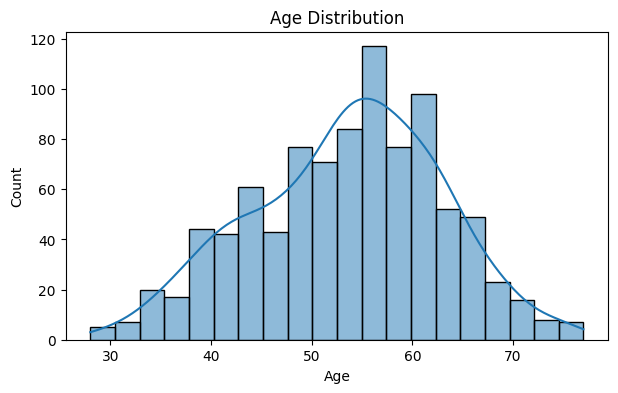

In [ ]:
# Histogram – Age
plt.figure(figsize=(7,4))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

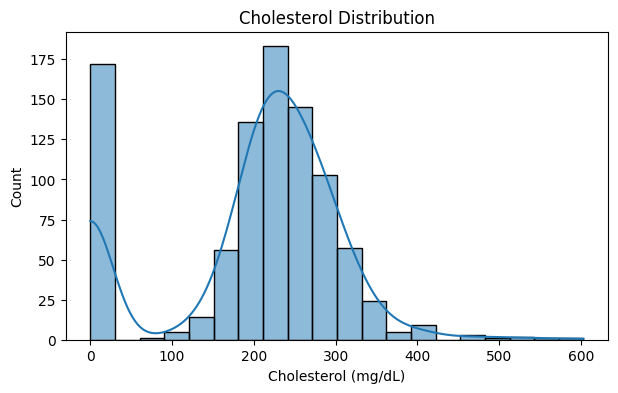

In [ ]:
# Histogram – Cholesterol
plt.figure(figsize=(7,4))
sns.histplot(df['Cholesterol'], bins=20, kde=True)
plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol (mg/dL)")
plt.ylabel("Count")
plt.show()

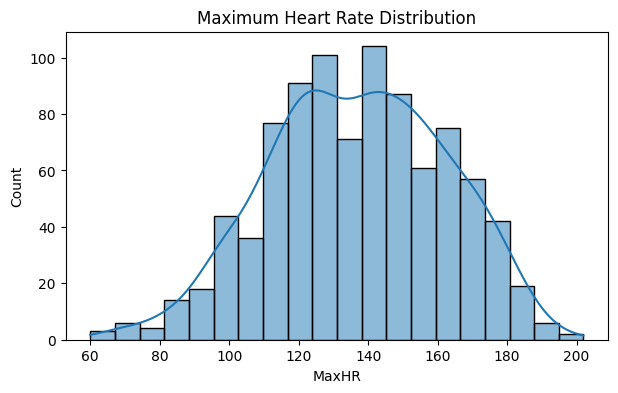

In [ ]:
#Histogram – MaxHR
plt.figure(figsize=(7,4))
sns.histplot(df['MaxHR'], bins=20, kde=True)
plt.title("Maximum Heart Rate Distribution")
plt.xlabel("MaxHR")
plt.ylabel("Count")
plt.show()

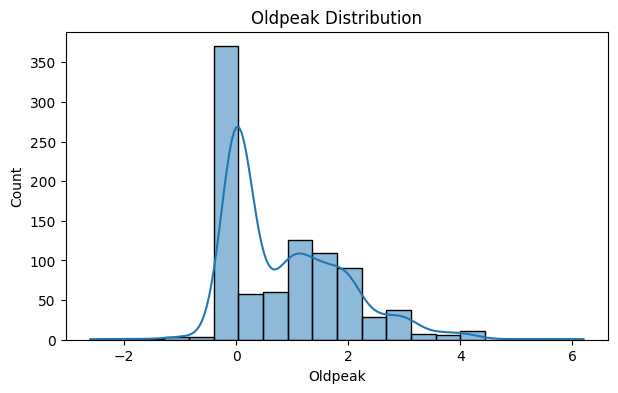

In [ ]:
# Histogram – Oldpeak
plt.figure(figsize=(7,4))
sns.histplot(df['Oldpeak'], bins=20, kde=True)
plt.title("Oldpeak Distribution")
plt.xlabel("Oldpeak")
plt.ylabel("Count")
plt.show()

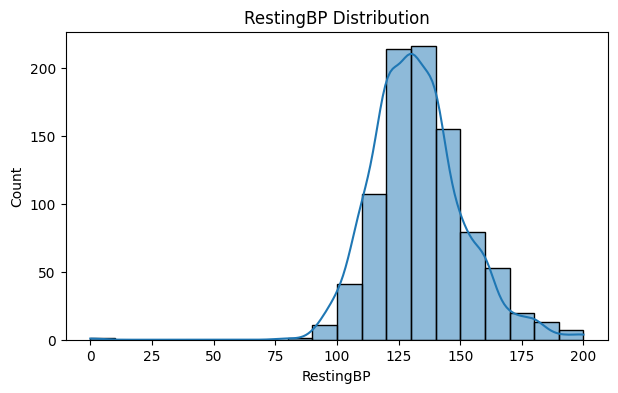

In [ ]:
# Histogram – RestinBP
plt.figure(figsize=(7,4))
sns.histplot(df['RestingBP'], bins=20, kde=True)
plt.title("RestingBP Distribution")
plt.xlabel("RestingBP")
plt.ylabel("Count")
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    int64  
 2   ChestPainType   918 non-null    int64  
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    int64  
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    int64  
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    int64  
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(11)
memory usage: 86.2 KB


# **Descriptive statistics**

In [ ]:
df.describe()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,0.781046,132.396514,198.799564,0.233115,0.989107,136.809368,0.404139,0.887364,1.361656,0.553377
std,9.432617,0.407701,0.956519,18.514154,109.384145,0.423046,0.631671,25.460334,0.490992,1.066570,0.607056,0.497414
min,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000,0.000000
25%,47.000000,1.000000,0.000000,120.000000,173.250000,0.000000,1.000000,120.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,0.000000,130.000000,223.000000,0.000000,1.000000,138.000000,0.000000,0.600000,1.000000,1.000000
75%,60.000000,1.000000,2.000000,140.000000,267.000000,0.000000,1.000000,156.000000,1.000000,1.500000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,1.000000


In [ ]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [ ]:
df.isna().sum() # Should be 0

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [ ]:
df.isnull().sum() # Should be 0

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [ ]:
from sklearn.preprocessing import StandardScaler

# Define continuous features
continuous_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# Standardize numeric columns
scaler = StandardScaler()
df[continuous_features] = scaler.fit_transform(df[continuous_features])

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,-1.433140,1,1,0.410909,0.825070,0,1,1.382928,0,-0.832432,2,0
1,-0.478484,0,2,1.491752,-0.171961,0,1,0.754157,0,0.105664,1,1
2,-1.751359,1,1,-0.129513,0.770188,0,2,-1.525138,0,-0.832432,2,0
3,-0.584556,0,0,0.302825,0.139040,0,1,-1.132156,1,0.574711,1,1
4,0.051881,1,2,0.951331,-0.034755,0,1,-0.581981,0,-0.832432,2,0


In [ ]:
df = pd.get_dummies(df, columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], drop_first=True)

In [ ]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,9.180000e+02,9.180000e+02,918.000000,918.000000,9.180000e+02,9.180000e+02,918.000000
mean,-1.083616e-16,1.954380e-16,0.000000,0.233115,4.953675e-16,1.238419e-16,0.553377
std,1.000545e+00,1.000545e+00,1.000545,0.423046,1.000545e+00,1.000545e+00,0.497414
min,-2.706015e+00,-7.154995e+00,-1.818435,0.000000,-3.018469e+00,-3.271482e+00,0.000000
25%,-6.906294e-01,-6.699346e-01,-0.233704,0.000000,-6.605778e-01,-8.324324e-01,0.000000
50%,5.188098e-02,-1.295128e-01,0.221363,0.000000,4.678968e-02,-2.695748e-01,1.000000
75%,6.883185e-01,4.109089e-01,0.623835,0.000000,7.541571e-01,5.747115e-01,1.000000
max,2.491558e+00,3.653439e+00,3.697252,1.000000,2.561874e+00,4.983762e+00,1.000000


In [ ]:
# standarization - only on numerical columns [0, 1]
scaler = MinMaxScaler()
df[['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']] = scaler.fit_transform(df[['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']])

In [ ]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_1,ChestPainType_1,ChestPainType_2,ChestPainType_3,RestingECG_1,RestingECG_2,ExerciseAngina_1,ST_Slope_1,ST_Slope_2
0,0.244898,0.70,0.479270,0,0.788732,0.295455,0,True,True,False,False,True,False,False,False,True
1,0.428571,0.80,0.298507,0,0.676056,0.409091,1,False,False,True,False,True,False,False,True,False
2,0.183673,0.65,0.469320,0,0.267606,0.295455,0,True,True,False,False,False,True,False,False,True
3,0.408163,0.69,0.354892,0,0.338028,0.465909,1,False,False,False,False,True,False,True,True,False
4,0.530612,0.75,0.323383,0,0.436620,0.295455,0,True,False,True,False,True,False,False,False,True


In [ ]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,0.520630,0.661983,0.329684,0.233115,0.540911,0.396291,0.553377
std,0.192502,0.092571,0.181400,0.423046,0.179298,0.121201,0.497414
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.387755,0.600000,0.287313,0.000000,0.422535,0.295455,0.000000
50%,0.530612,0.650000,0.369818,0.000000,0.549296,0.363636,1.000000
75%,0.653061,0.700000,0.442786,0.000000,0.676056,0.465909,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
# Low std → values are close to the mean → less variability
# High std → values are more spread out → more variability
mean_values = df.mean()
median_values = df.median()
std_values = df.std()
min_values = df.min()
max_values = df.max()

print("Mean:\n", mean_values)
print("Median:\n", median_values)
print("Standard Deviation:\n", std_values) # Std → how much values vary around that center
print("Minimum:\n", min_values)
print("Maximum:\n", max_values)

Mean:
 Age                 0.520630
RestingBP           0.661983
Cholesterol         0.329684
FastingBS           0.233115
MaxHR               0.540911
Oldpeak             0.396291
HeartDisease        0.553377
Sex_1               0.789760
ChestPainType_1     0.188453
ChestPainType_2     0.221133
ChestPainType_3     0.050109
RestingECG_1        0.601307
RestingECG_2        0.193900
ExerciseAngina_1    0.404139
ST_Slope_1          0.501089
ST_Slope_2          0.430283
dtype: float64
Median:
 Age                 0.530612
RestingBP           0.650000
Cholesterol         0.369818
FastingBS           0.000000
MaxHR               0.549296
Oldpeak             0.363636
HeartDisease        1.000000
Sex_1               1.000000
ChestPainType_1     0.000000
ChestPainType_2     0.000000
ChestPainType_3     0.000000
RestingECG_1        1.000000
RestingECG_2        0.000000
ExerciseAngina_1    0.000000
ST_Slope_1          1.000000
ST_Slope_2          0.000000
dtype: float64
Standard Deviation:
 Age  

# **Correlation**

**Pearson Correlation values range from -1 to 1.** Here's a General guideline:

**Absolute correlation**  - **Strength**

0.0 - 0.19	            Very weak

0.2 - 0.39	            Weak / low

0.4 - 0.59	            Moderate

0.6 - 0.79	            Strong

0.8 - 1.0	              Very strong

                       Age  RestingBP  Cholesterol  FastingBS     MaxHR  \
Age               1.000000   0.254399    -0.095282   0.198039 -0.382045   
RestingBP         0.254399   1.000000     0.100893   0.070193 -0.112135   
Cholesterol      -0.095282   0.100893     1.000000  -0.260974  0.235792   
FastingBS         0.198039   0.070193    -0.260974   1.000000 -0.131438   
MaxHR            -0.382045  -0.112135     0.235792  -0.131438  1.000000   
Oldpeak           0.258612   0.164803     0.050148   0.052698 -0.160691   
HeartDisease      0.282039   0.107589    -0.232741   0.267291 -0.400421   
Sex_1             0.055750   0.005133    -0.200092   0.120076 -0.189186   
ChestPainType_1  -0.218165  -0.046153     0.150954  -0.140514  0.253735   
ChestPainType_2  -0.011335  -0.041348    -0.006634  -0.039249  0.134580   
ChestPainType_3   0.032042   0.049855     0.017365   0.026885  0.100025   
RestingECG_1     -0.230566  -0.116851    -0.038470  -0.093028  0.023801   
RestingECG_2      0.13679

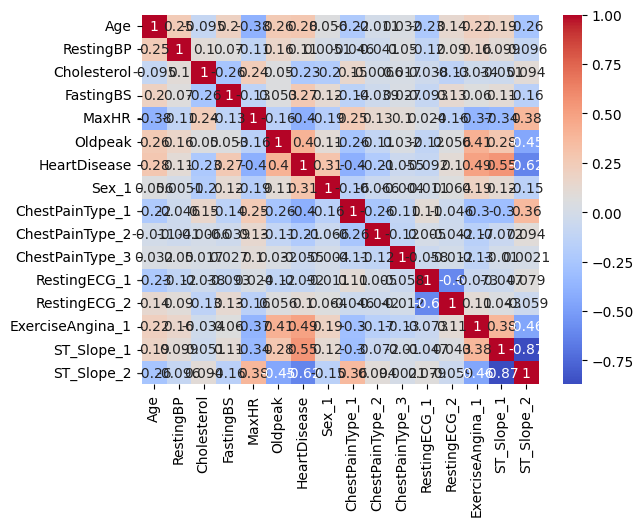

In [ ]:
# Pearson correlation
pearson_corr = df.corr(method='pearson')
print(pearson_corr)

sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.show()

## Values range from -1 to 1
#  1 → perfect positive correlation
# -1 → perfect negative correlation
# 0 → no correlation

**Strong positive correlations**

* ST_Slope_1 vs HeartDisease = 0.55 → a higher ST slope (type 1) is associated with heart disease.
* ExerciseAngina_1 vs HeartDisease = 0.49 → patients with exercise-induced angina tend to have heart disease.
* Oldpeak vs HeartDisease = 0.40 → higher ST depression during exercise is associated with heart disease.

**Strong negative correlations**

* ST_Slope_2 vs HeartDisease = -0.62 → type 2 ST slope is associated with lower risk of heart disease.
* MaxHR vs HeartDisease = -0.40 → lower maximum heart rate is associated with heart disease.
* RestingECG_1 vs RestingECG_2 = -0.60 → these two ECG types are negatively correlated (expected since they are different categories).
* ST_Slope_1 vs ST_Slope_2 = -0.87 → almost perfectly inversely related (these are mutually exclusive categories).

**Moderate correlations**

* Age vs MaxHR = -0.38 → older patients tend to have lower max heart rate.
* Age vs HeartDisease = 0.28 → older patients have slightly higher risk.
* ExerciseAngina_1 vs MaxHR = -0.37 → those with angina tend to have lower max heart rate.

**Weak correlations**

* Most other variables, especially Cholesterol, FastingBS, Sex_1, have weak correlations with other numeric variables (<0.3).
* This suggests these variables are less linearly associated with heart disease or each other in your dataset.

                       Age  RestingBP  Cholesterol  FastingBS     MaxHR  \
Age               1.000000   0.279390    -0.047156   0.201015 -0.365025   
RestingBP         0.279390   1.000000     0.109481   0.066019 -0.107566   
Cholesterol      -0.047156   0.109481     1.000000  -0.192871  0.183900   
FastingBS         0.201015   0.066019    -0.192871   1.000000 -0.124527   
MaxHR            -0.365025  -0.107566     0.183900  -0.124527  1.000000   
Oldpeak           0.298250   0.175313     0.051723   0.098968 -0.205113   
HeartDisease      0.289576   0.113866    -0.139873   0.267291 -0.404827   
Sex_1             0.059940   0.026817    -0.181370   0.120076 -0.195850   
ChestPainType_1  -0.213471  -0.064109     0.123477  -0.140514  0.256259   
ChestPainType_2  -0.027328  -0.029418    -0.040342  -0.039249  0.140868   
ChestPainType_3   0.050918   0.056829     0.005189   0.026885  0.097394   
RestingECG_1     -0.240570  -0.107680    -0.057556  -0.093028  0.032388   
RestingECG_2      0.14105

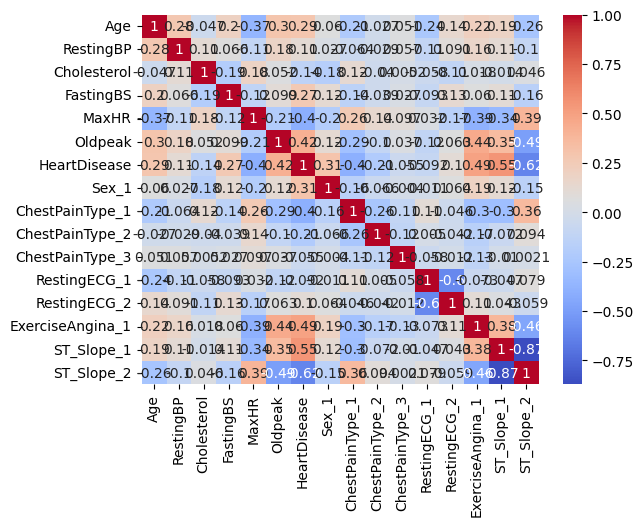

In [ ]:
# Spearman correlation
spearman_corr = df.corr(method='spearman')
print(spearman_corr)

sns.heatmap(spearman_corr, annot=True, cmap='coolwarm')
plt.show()

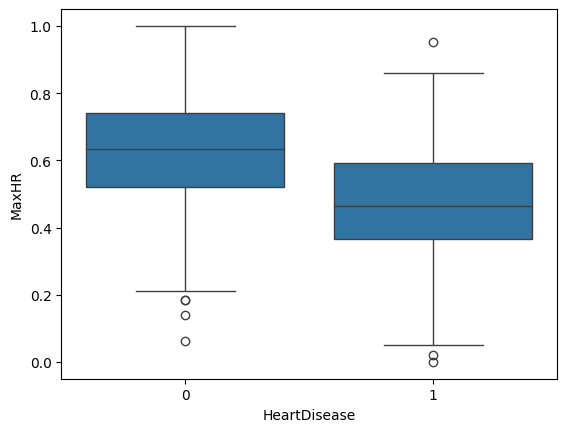

In [ ]:
sns.boxplot(x='HeartDisease', y='MaxHR', data=df)
plt.show()

## what do we see in this graph?
# we can see patterns:
# Most 1’s (diseased) cluster at lower MaxHR
# Most 0’s (healthy) cluster at higher MaxHR

# **Correlation for Sub-groups**

In [ ]:
print(df.columns)

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_1', 'ChestPainType_1', 'ChestPainType_2',
       'ChestPainType_3', 'RestingECG_1', 'RestingECG_2', 'ExerciseAngina_1',
       'ST_Slope_1', 'ST_Slope_2'],
      dtype='object')


1. **MALE** VS **FEMALE**

In [ ]:
# Correlation for Females only
female_corr = df[df['Sex_1'] == 0][['RestingBP', 'MaxHR', 'HeartDisease']].corr()
print(female_corr)

              RestingBP     MaxHR  HeartDisease
RestingBP      1.000000 -0.092007      0.299215
MaxHR         -0.092007  1.000000     -0.222635
HeartDisease   0.299215 -0.222635      1.000000


In [ ]:
# Correlation for males only
df[df['Sex_1'] == 1][['RestingBP', 'MaxHR', 'HeartDisease']].corr(method='pearson')

,RestingBP,MaxHR,HeartDisease
RestingBP,1.000000,-0.118825,0.063526
MaxHR,-0.118825,1.000000,-0.396443
HeartDisease,0.063526,-0.396443,1.000000


In [ ]:
df[df['Sex_1'] == 1][['RestingBP', 'MaxHR', 'HeartDisease']].corr(method='spearman')

,RestingBP,MaxHR,HeartDisease
RestingBP,1.000000,-0.114221,0.069423
MaxHR,-0.114221,1.000000,-0.399973
HeartDisease,0.069423,-0.399973,1.000000


2. HEART DISEASE

In [ ]:
df[df['HeartDisease'] == 1][['Age', 'Cholesterol', 'MaxHR']].corr(method='pearson')

,Age,Cholesterol,MaxHR
Age,1.000000,-0.041392,-0.246705
Cholesterol,-0.041392,1.000000,0.187556
MaxHR,-0.246705,0.187556,1.000000


Δοκιμασα το κορελεσιον με πεαρσον κ spearman - εχουν μικρες αποκλισεις.

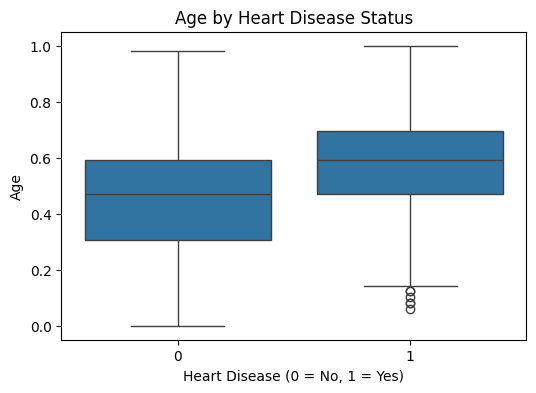

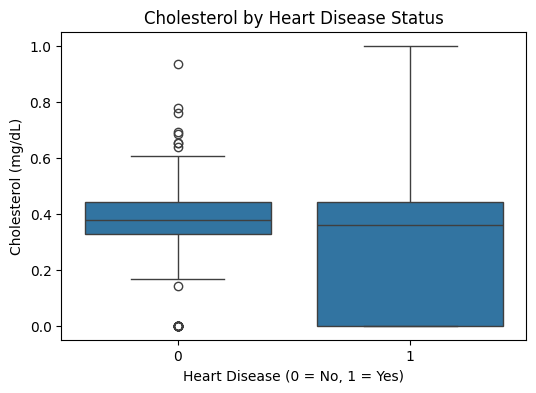

In [ ]:
# Boxplot – Age vs HeartDisease
plt.figure(figsize=(6,4))
sns.boxplot(x='HeartDisease', y='Age', data=df)
plt.title("Age by Heart Disease Status")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()


# Boxplot – Cholesterol vs HeartDisease
plt.figure(figsize=(6,4))
sns.boxplot(x='HeartDisease', y='Cholesterol', data=df)
plt.title("Cholesterol by Heart Disease Status")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Cholesterol (mg/dL)")
plt.show()


# **Graphs**

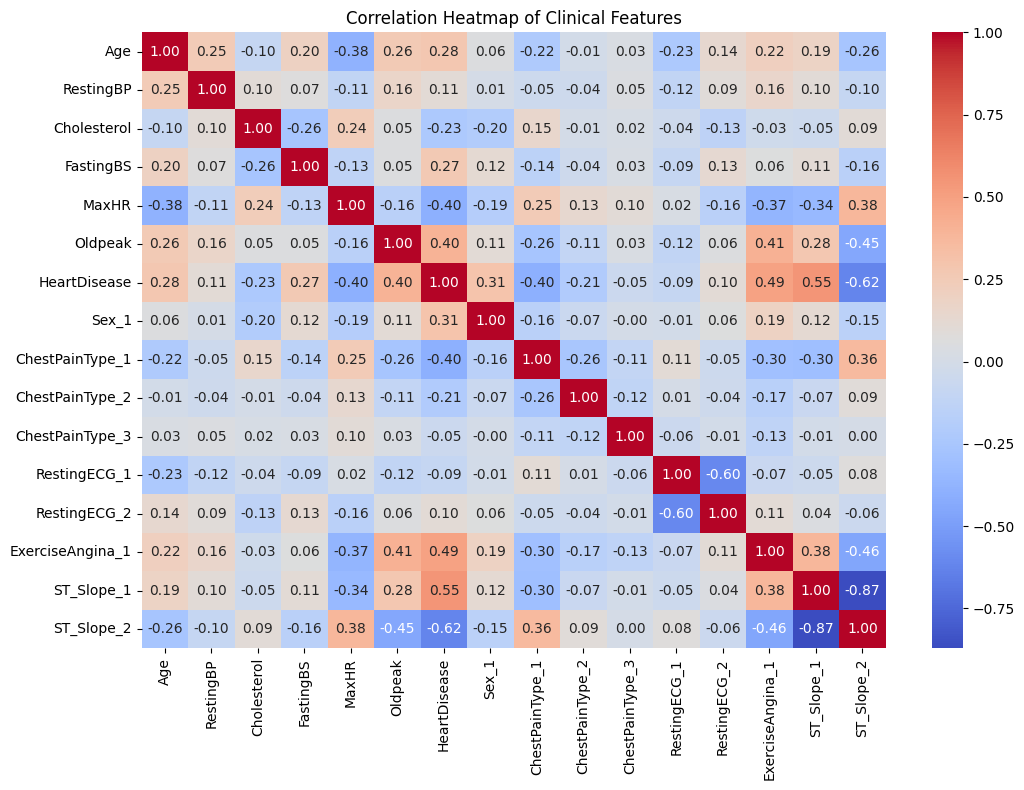

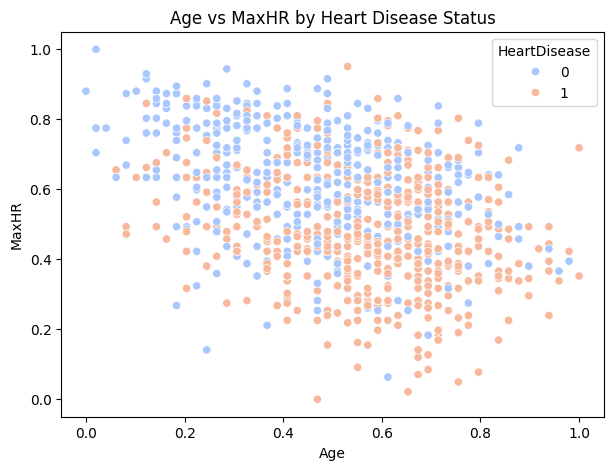

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(12,8))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Clinical Features")
plt.show()


# Scatterplot – Age vs MaxHR, colored by HeartDisease
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='Age', y='MaxHR', hue='HeartDisease', palette='coolwarm')
plt.title("Age vs MaxHR by Heart Disease Status")
plt.xlabel("Age")
plt.ylabel("MaxHR")
plt.show()

In [ ]:
print(df.columns)

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_1', 'ChestPainType_1', 'ChestPainType_2',
       'ChestPainType_3', 'RestingECG_1', 'RestingECG_2', 'ExerciseAngina_1',
       'ST_Slope_1', 'ST_Slope_2'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               918 non-null    float64
 1   RestingBP         918 non-null    float64
 2   Cholesterol       918 non-null    float64
 3   FastingBS         918 non-null    int64  
 4   MaxHR             918 non-null    float64
 5   Oldpeak           918 non-null    float64
 6   HeartDisease      918 non-null    int64  
 7   Sex_1             918 non-null    bool   
 8   ChestPainType_1   918 non-null    bool   
 9   ChestPainType_2   918 non-null    bool   
 10  ChestPainType_3   918 non-null    bool   
 11  RestingECG_1      918 non-null    bool   
 12  RestingECG_2      918 non-null    bool   
 13  ExerciseAngina_1  918 non-null    bool   
 14  ST_Slope_1        918 non-null    bool   
 15  ST_Slope_2        918 non-null    bool   
dtypes: bool(9), float64(5), int64(2)
memory usag